<a href="https://colab.research.google.com/github/syeda-bisma05/pokemon-data-analysis/blob/main/Pokemon_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pokemon Data Analysis

This project explores the stats of 801 Pokemon, such as attack, defense, speed and type. The goal is to find out what makes a Pokemon strong and whether legendary Pokemon are really more powerful.

## Data Card

**Source:** Kaggle, "Pokemon Complete Stats" dataset
**One row means:** one Pokemon
**Rows:** 801
**Columns used:** 16 (selected from the original 41)

| Column | Meaning |
|---|---|
| name | Name of the Pokemon |
| type1, type2 | Main type and second type (for example fire, water). Some Pokemon have only one type |
| generation | The game series the Pokemon first appeared in (1 to 7) |
| is_legendary | 1 = legendary Pokemon, 0 = normal Pokemon |
| hp | Health points (how much damage it can take) |
| attack, defense | Strength of normal attacks and normal defense |
| sp_attack, sp_defense | Strength of special attacks and special defense |
| speed | How fast the Pokemon is |
| base_total | Sum of all six stats (overall power) |
| height_m, weight_kg | Height in meters and weight in kilograms |
| capture_rate | How hard it is to catch the Pokemon |
| percentage_male | Percentage of the species that is male |

## Step 1: Understand the Data

In [1]:
from google.colab import files
uploaded = files.upload()

Saving pokemon.csv to pokemon.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
df = pd.read_csv('pokemon.csv')

In [4]:
df.shape

(801, 41)

**Observation:** The original data has 801 rows (Pokemon) and 41 columns. This is too many columns for my questions, so I will select the useful ones.

In [5]:
df.head()

,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,...,percentage_male,pokedex_number,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,1,65,65,45,grass,poison,6.9,1,0
1,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,2,80,80,60,grass,poison,13.0,1,0
2,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,3,122,120,80,grass,poison,100.0,1,0
3,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,4,60,50,65,fire,NaN,8.5,1,0
4,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,5,80,65,80,fire,NaN,19.0,1,0


**Observation:** Each row is one Pokemon, and the table has many columns such as abilities, type effectiveness (against_...) and battle stats. The original data is wide, so only the useful columns need to be kept.

In [6]:
df.columns

Index(['abilities', 'against_bug', 'against_dark', 'against_dragon',
       'against_electric', 'against_fairy', 'against_fight', 'against_fire',
       'against_flying', 'against_ghost', 'against_grass', 'against_ground',
       'against_ice', 'against_normal', 'against_poison', 'against_psychic',
       'against_rock', 'against_steel', 'against_water', 'attack',
       'base_egg_steps', 'base_happiness', 'base_total', 'capture_rate',
       'classfication', 'defense', 'experience_growth', 'height_m', 'hp',
       'japanese_name', 'name', 'percentage_male', 'pokedex_number',
       'sp_attack', 'sp_defense', 'speed', 'type1', 'type2', 'weight_kg',
       'generation', 'is_legendary'],
      dtype='object')

**Observation:** The columns include 18 "against_" columns, battle stats (hp, attack, defense, speed), type, generation and is_legendary. Only the stats, types and body measurements are useful for my questions.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   abilities          801 non-null    object 
 1   against_bug        801 non-null    float64
 2   against_dark       801 non-null    float64
 3   against_dragon     801 non-null    float64
 4   against_electric   801 non-null    float64
 5   against_fairy      801 non-null    float64
 6   against_fight      801 non-null    float64
 7   against_fire       801 non-null    float64
 8   against_flying     801 non-null    float64
 9   against_ghost      801 non-null    float64
 10  against_grass      801 non-null    float64
 11  against_ground     801 non-null    float64
 12  against_ice        801 non-null    float64
 13  against_normal     801 non-null    float64
 14  against_poison     801 non-null    float64
 15  against_psychic    801 non-null    float64
 16  against_rock       801 non

**Observation:** Most columns have all 801 values, but type2 has only 417, percentage_male has 703, and height_m and weight_kg have 781. The column capture_rate is stored as text (object), so it must be converted to numbers later.

In [9]:
cols = ['name', 'type1', 'type2', 'generation', 'is_legendary',
        'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed',
        'base_total', 'height_m', 'weight_kg', 'capture_rate', 'percentage_male']

df = df[cols].copy()

In [ ]:
df.shape

(801, 16)

**Observation:** After keeping only the useful columns, the table has 801 rows and 16 columns. This is easier to work with and still has both numeric and category columns.

In [10]:

df.head()

,name,type1,type2,generation,is_legendary,hp,attack,defense,sp_attack,sp_defense,speed,base_total,height_m,weight_kg,capture_rate,percentage_male
0,Bulbasaur,grass,poison,1,0,45,49,49,65,65,45,318,0.7,6.9,45,88.1
1,Ivysaur,grass,poison,1,0,60,62,63,80,80,60,405,1.0,13.0,45,88.1
2,Venusaur,grass,poison,1,0,80,100,123,122,120,80,625,2.0,100.0,45,88.1
3,Charmander,fire,NaN,1,0,39,52,43,60,50,65,309,0.6,8.5,45,88.1
4,Charmeleon,fire,NaN,1,0,58,64,58,80,65,80,405,1.1,19.0,45,88.1


**Observation:** The first 5 rows are generation 1 Pokemon and all are non-legendary. Charmander and Charmeleon have NaN in type2 because they have only one type. The capture_rate looks like a number (45) but is stored as text, so it will be converted in the cleaning step.

In [11]:
df.describe()

,generation,is_legendary,hp,attack,defense,sp_attack,sp_defense,speed,base_total,height_m,weight_kg,percentage_male
count,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,781.000000,781.000000,703.000000
mean,3.690387,0.087391,68.958801,77.857678,73.008739,71.305868,70.911361,66.334582,428.377029,1.163892,61.378105,55.155761
std,1.930420,0.282583,26.576015,32.158820,30.769159,32.353826,27.942501,28.907662,119.203577,1.080326,109.354766,20.261623
min,1.000000,0.000000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,180.000000,0.100000,0.100000,0.000000
25%,2.000000,0.000000,50.000000,55.000000,50.000000,45.000000,50.000000,45.000000,320.000000,0.600000,9.000000,50.000000
50%,4.000000,0.000000,65.000000,75.000000,70.000000,65.000000,66.000000,65.000000,435.000000,1.000000,27.300000,50.000000
75%,5.000000,0.000000,80.000000,100.000000,90.000000,91.000000,90.000000,85.000000,505.000000,1.500000,64.800000,50.000000
max,7.000000,1.000000,255.000000,185.000000,230.000000,194.000000,230.000000,180.000000,780.000000,14.500000,999.900000,100.000000


**Observation:** Most columns have 801 values, but height_m and weight_kg have 781 and percentage_male has only 703, so they have missing values. The mean base_total is about 428 and the median is 435, so the typical Pokemon is fairly balanced. Weight (max 999.9 vs median 27.3), height (max 14.5 vs median 1.0) and hp (max 255 vs mean 69) have very large maximum values, which hints at outliers. About 8.7% of Pokemon are legendary (mean of is_legendary is 0.087).

## Step 2: Questions

**One column (univariate)**
1. How is the overall power (base_total) of Pokemon distributed?
2. Which primary type (type1) has the most Pokemon?
3. How many Pokemon are legendary and how many are normal?

**Two columns (bivariate)**

4. What is the relationship between attack and defense?
5. What is the relationship between height and weight?

**Comparing groups**

6. Are legendary Pokemon really stronger than normal Pokemon?
7. Which type has the highest average base_total?
8. Which generation has the most legendary Pokemon?

## Step 3: Data Cleaning


### 1: Handle Missing Value

In [12]:
# her columns main kitni values missing hain
missing = df.isnull().sum()
missing

,0
name,0
type1,0
type2,384
generation,0
is_legendary,0
hp,0
attack,0
defense,0
sp_attack,0
sp_defense,0


**Observation:** Only 4 columns have missing values: type2 (384), percentage_male (98), height_m (20) and weight_kg (20). The other 12 columns are complete.

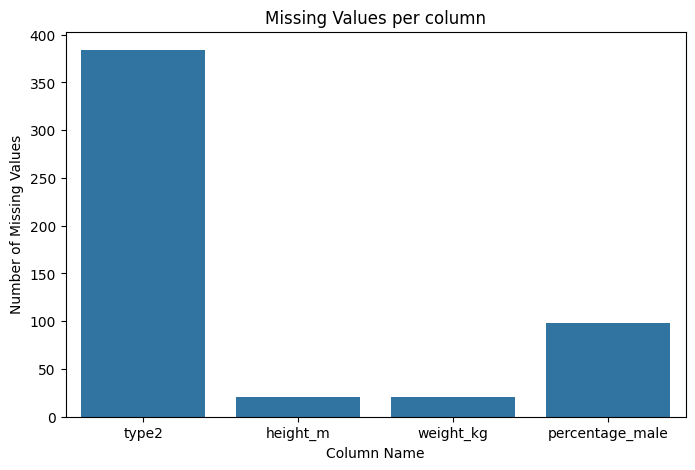

In [13]:
# sirf wu columns lo jin main missing values hain
missing = df.isnull().sum()
missing = missing[missing > 0]

# bar graph
plt.figure(figsize=(8,5))
sns.barplot(x = missing.index, y = missing.values)
plt.title('Missing Values per column')
plt.xlabel('Column Name')
plt.ylabel('Number of Missing Values')
plt.show()

**Observation:** type2 has by far the most missing values (384), followed by percentage_male (98). height_m and weight_kg have only 20 each.

**Decision:**
- type2: fill with "None" because a missing value just means the Pokemon has only one type.
- height_m and weight_kg: fill with the median, because only 20 rows are missing and the median is not affected by extreme values.
- percentage_male: fill with the median, because dropping 98 rows would lose too much data.

In [14]:
# type2 khali h means pokemon ki sirf aik type h, is lye none likhdu
df['type2'] = df['type2'].fillna('None')

# baqi 3 columns ku median se fill karu
for col in ['height_m', 'weight_kg', 'percentage_male']:
  df[col] = df[col].fillna(df[col].median())

# check karu ke ab koi missing value bachi h ke nahi
print(df.isnull().sum())

name               0
type1              0
type2              0
generation         0
is_legendary       0
hp                 0
attack             0
defense            0
sp_attack          0
sp_defense         0
speed              0
base_total         0
height_m           0
weight_kg          0
capture_rate       0
percentage_male    0
dtype: int64


**Observation:** After filling, all 16 columns now show 0 missing values. The dataset is complete and ready for the next cleaning steps.

### 2: Handle Duplicates

In [15]:
# kitni rows bilkul same (repeat) hain?
print('Duplicate rows: ', df.duplicated().sum())

Duplicate rows:  0


**Observation:** The dataset has 0 duplicate rows, so no rows need to be removed. This confirms that every row is a different Pokemon.

### 3: Handle Wrong Data Types

In [16]:
# pehle dekhu capture_rate ka type kia h
print('Before: ', df['capture_rate'].dtype)

# Text mein se pehla number nikalo, phir usay integer (poora number) banao
# (is dataset mein kisi ek Pokemon ki value mein 2 numbers likhe hote hain, is liye pehla number lete hain)
df['capture_rate'] = df["capture_rate"].astype(str).str.extract(r"(\d+)")[0].astype(int)

# ab dubara check karu
print('After: ', df['capture_rate'].dtype)


Before:  object
After:  int64


**Observation:** capture_rate was stored as text (object) and is now a number (int64). This lets us calculate averages and draw graphs with it.

### 4: Outliers

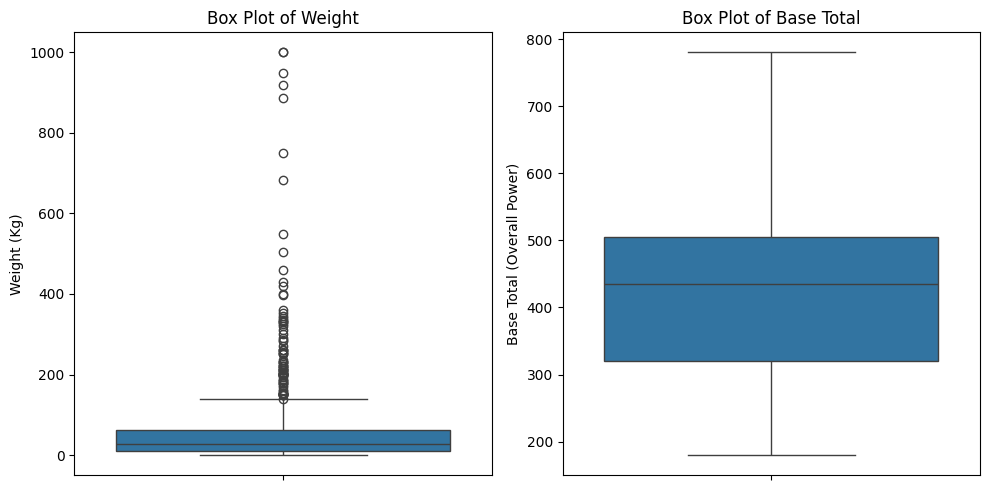

In [17]:
# 2 box plot aik sath banua
fig, axes = plt.subplots(1, 2, figsize = (10,5))

sns.boxplot(y = df['weight_kg'], ax = axes[0])
axes[0].set_title('Box Plot of Weight')
axes[0].set_ylabel('Weight (Kg)')

sns.boxplot(y = df['base_total'], ax = axes[1])
axes[1].set_title('Box Plot of Base Total')
axes[1].set_ylabel('Base Total (Overall Power)')

plt.tight_layout()
plt.show()

**Observation:** weight_kg has many outliers, with some Pokemon weighing close to 1000 kg while most are under 100 kg. base_total has no visible outliers, and its values are spread fairly evenly.

In [18]:
# IQR rule: outlier wu value h ju normal range se bahar hu
results = []  # khaali dibba, har column ka result yahan jama hoga (ye line loop se PEHLE honi chahiye)

for col in ['weight_kg', 'base_total']:
  Q1 = df[col].quantile(0.25)    # neeche wala 25% part
  Q3 = df[col].quantile(0.75)    # upper waala 25% part
  IQR = Q3 - Q1                  # beech ka 50% part
  lower = Q1 - 1.5 * IQR         # lower limit
  upper = Q3 + 1.5 * IQR        # upper limit

  # Wo rows jo lower se chhoti ya upper se bari hain
  outliers = df[(df[col] < lower) | (df[col] > upper)]

  # Result list mein save karo
  results.append([col, round(lower, 1), round(upper, 1), len(outliers)])

# Result ko ek saaf table mein dikhao
pd.DataFrame(results, columns=["Column", "Lower Limit", "Upper Limit", "Outliers"])

,Column,Lower Limit,Upper Limit,Outliers
0,weight_kg,-69.0,139.8,82
1,base_total,42.5,782.5,0


**Observation:** weight_kg has 82 outliers above the upper limit of 139.8 kg, while base_total has 0 outliers. This matches the box plots.

In [19]:
# Sabse bhaari 10 Pokemon dekho
df.sort_values("weight_kg", ascending=False)[["name", "type1", "weight_kg", "is_legendary"]].head(10)

,name,type1,weight_kg,is_legendary
796,Celesteela,steel,999.9,1
789,Cosmoem,psychic,999.9,1
382,Groudon,ground,950.0,1
749,Mudsdale,ground,920.0,0
798,Guzzlord,dark,888.0,1
486,Giratina,ghost,750.0,1
482,Dialga,steel,683.0,1
375,Metagross,steel,550.0,0
712,Avalugg,ice,505.0,0
142,Snorlax,normal,460.0,0


**Observation:** The 10 heaviest Pokemon include 6 legendary ones such as Celesteela and Groudon, plus big normal ones like Snorlax. These are real heavy Pokemon, not data errors.

**Decision:** I decided to KEEP the weight_kg outliers. They are real, very heavy Pokemon, not mistakes. Removing them would delete valid data and change the results. base_total has no outliers, so nothing needs to be done there.

## Step 4: Univariate Analysis

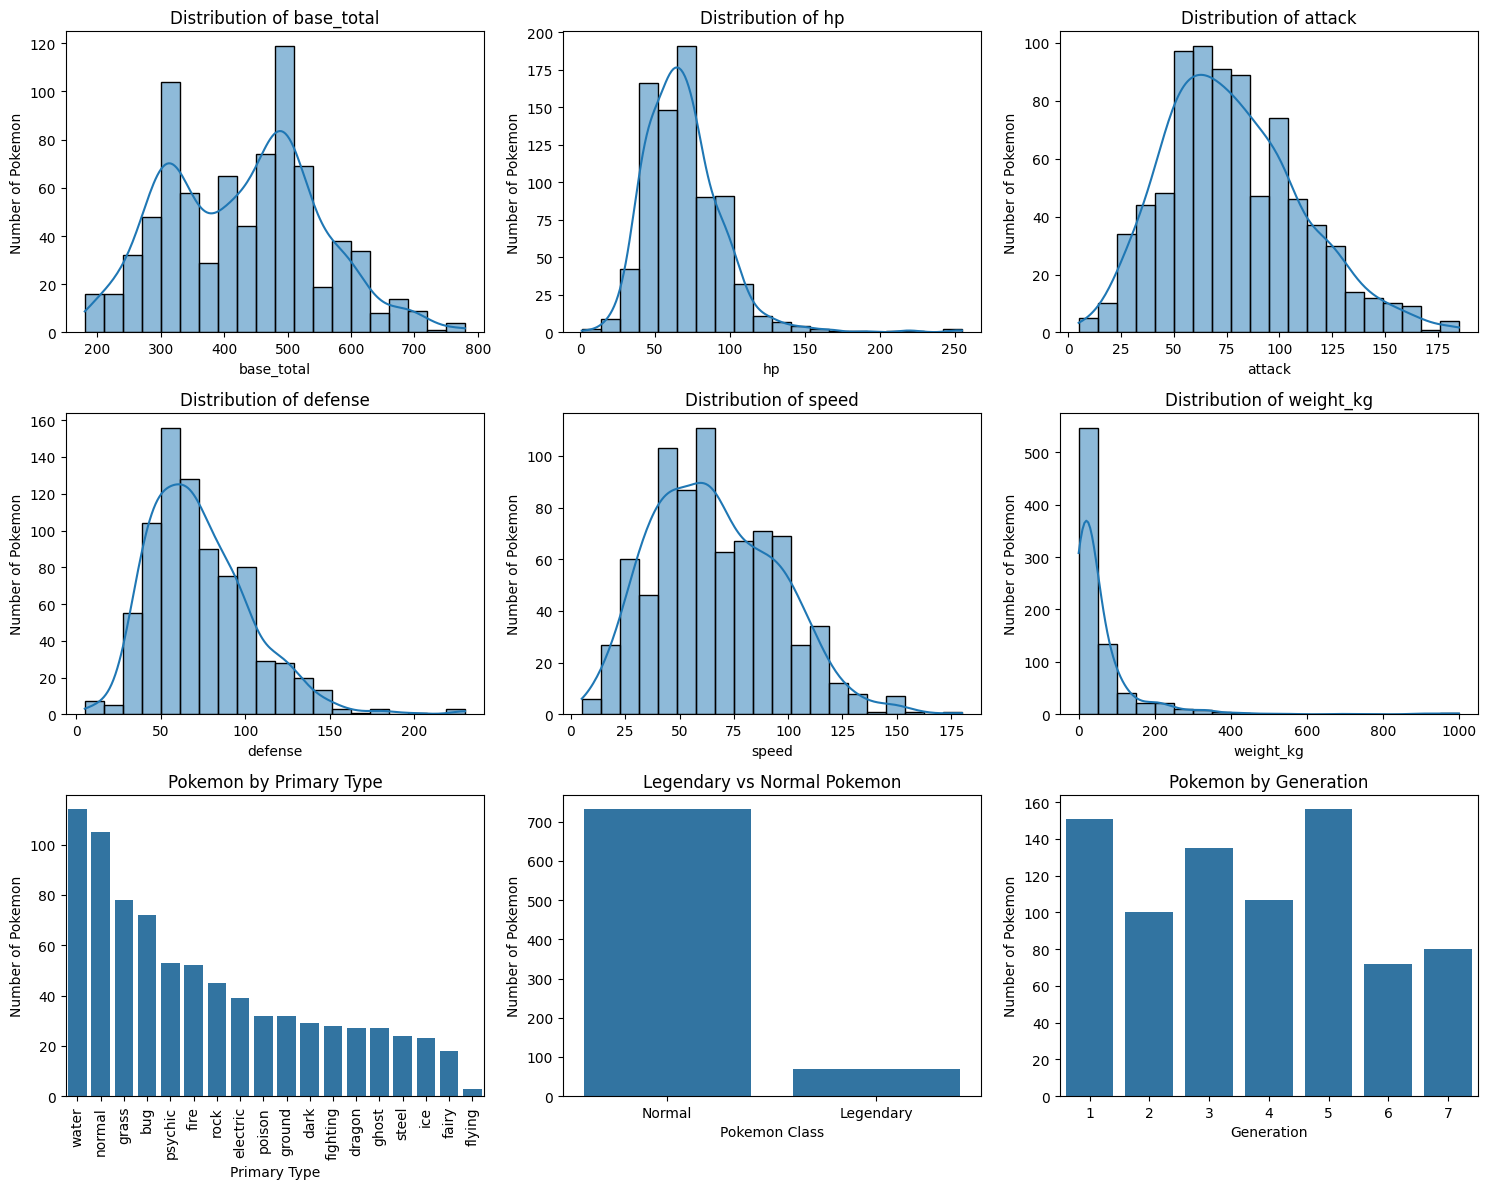

In [20]:
# 3 rows x 3 columns ka ek bada page banao (9 graph ki jagah)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()  # 3x3 ko ek seedhi list bana do: axes[0] se axes[8] tak

# Pehle 6 graph: numbers wale columns ke histograms
numeric_cols = ["base_total", "hp", "attack", "defense", "speed", "weight_kg"]
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[i])
    axes[i].set_title("Distribution of " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Pokemon")

# 7wan graph: type1 ke Pokemon ki ginti
sns.countplot(data=df, x="type1", order=df["type1"].value_counts().index, ax=axes[6])
axes[6].set_title("Pokemon by Primary Type")
axes[6].set_xlabel("Primary Type")
axes[6].set_ylabel("Number of Pokemon")
axes[6].tick_params(axis="x", rotation=90)  # naam seedhe khade kar do

# 8wan graph: legendary vs normal
sns.countplot(data=df, x="is_legendary", ax=axes[7])
axes[7].set_title("Legendary vs Normal Pokemon")
axes[7].set_xlabel("Pokemon Class")
axes[7].set_ylabel("Number of Pokemon")
axes[7].set_xticks([0, 1])
axes[7].set_xticklabels(["Normal", "Legendary"])

# 9wan graph: generation ke Pokemon ki ginti
sns.countplot(data=df, x="generation", ax=axes[8])
axes[8].set_title("Pokemon by Generation")
axes[8].set_xlabel("Generation")
axes[8].set_ylabel("Number of Pokemon")

plt.tight_layout()  # graph aapas mein na takrayen
plt.show()

**Observations (Step 4):**
1. **base_total:** Two peaks around 300 and 500, and very few Pokemon above 650.
2. **hp:** Most Pokemon have hp between 50 and 80, and only a few go above 150.
3. **attack:** Roughly bell-shaped, with most values between 50 and 100.
4. **defense:** Most values are between 40 and 90, with a few very high ones above 200.
5. **speed:** Spread out widely, with most Pokemon between 30 and 100.
6. **weight_kg:** Strongly right-skewed, as most Pokemon weigh under 100 kg and a few are near 1000 kg.
7. **type1:** Water and normal are the most common types (above 100 each), and flying is the rarest.
8. **Legendary vs Normal:** The dataset has about 730 normal and only about 70 legendary Pokemon.
9. **Generation:** Generation 5 and generation 1 have the most Pokemon, and generation 6 has the fewest.

## Step 5: Bivariate Analysis

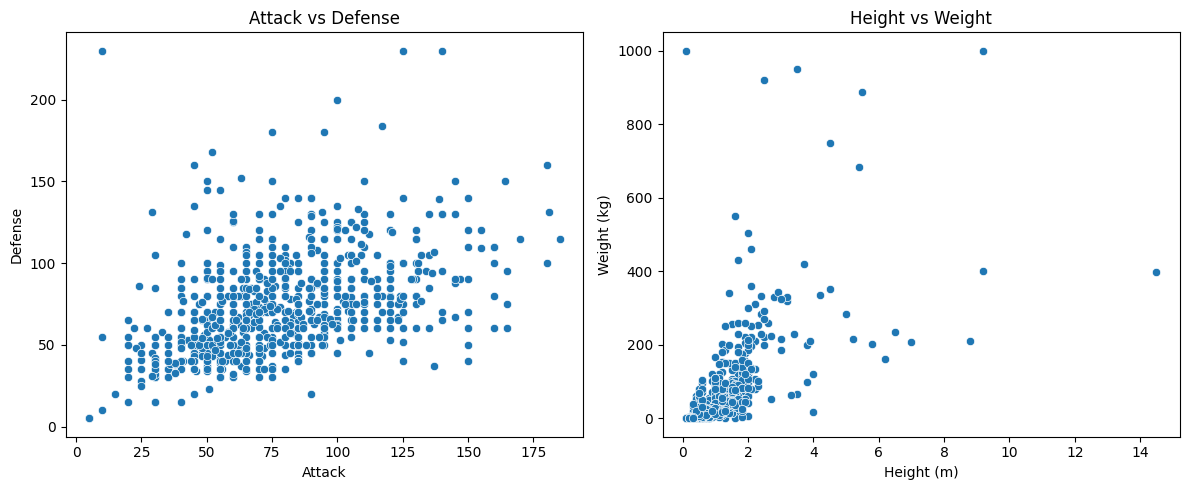

In [21]:
# 1 qatar, 2 column ka page
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Attack vs Defense
sns.scatterplot(data=df, x="attack", y="defense", ax=axes[0])
axes[0].set_title("Attack vs Defense")
axes[0].set_xlabel("Attack")
axes[0].set_ylabel("Defense")

# Height vs Weight
sns.scatterplot(data=df, x="height_m", y="weight_kg", ax=axes[1])
axes[1].set_title("Height vs Weight")
axes[1].set_xlabel("Height (m)")
axes[1].set_ylabel("Weight (kg)")

plt.tight_layout()
plt.show()

**Observation (Attack vs Defense):** The dots slope upward, so Pokemon with higher attack usually have higher defense. The relationship is positive but weak, because the points are widely spread.

**Observation (Height vs Weight):** Taller Pokemon are generally heavier, so the relationship is positive. Most Pokemon are small and light, and a few extreme points are far from the rest.

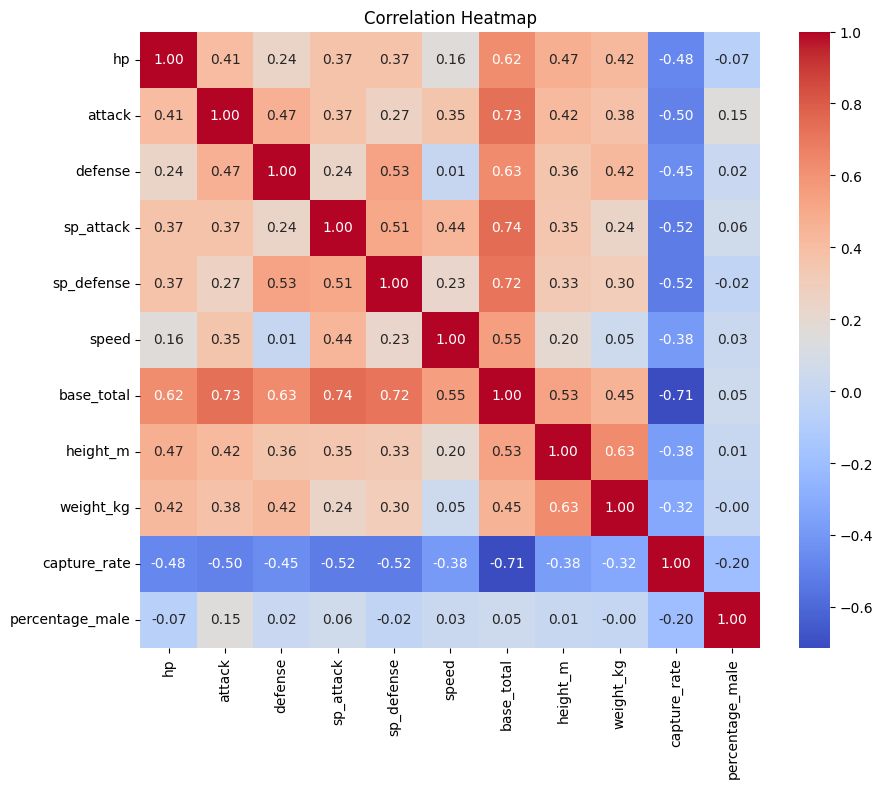

In [22]:
# Sirf number wale columns lo aur dekho kaun kis se juda hai
num_cols = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed",
            "base_total", "height_m", "weight_kg", "capture_rate", "percentage_male"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** base_total has strong positive links with attack, sp_attack and sp_defense (about 0.72 to 0.74), which is expected because it is their sum. capture_rate has a strong negative link with base_total (-0.71), so stronger Pokemon are harder to catch.

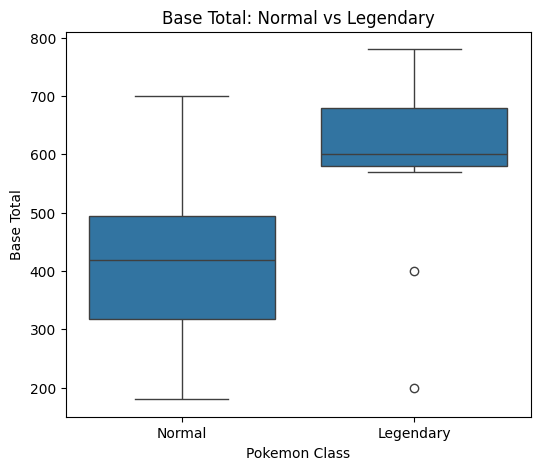

In [23]:
# Legendary aur normal Pokemon ki power ka muqabla
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="is_legendary", y="base_total")
plt.title("Base Total: Normal vs Legendary")
plt.xlabel("Pokemon Class")
plt.ylabel("Base Total")
plt.xticks([0, 1], ["Normal", "Legendary"])
plt.show()

**Observation:** Legendary Pokemon have a much higher median base_total (about 600) than normal Pokemon (about 420). Their whole box sits above the normal box, so legendary Pokemon are generally stronger.